<a href="https://colab.research.google.com/github/andrehochuli/teaching/blob/main/ComputerVision/Lecture%2007%20-%20CNN%20Implementation/Exercicio_Simpsons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#The Simpsons classification

In [1]:
import numpy as np
import cv2, glob
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import datasets, layers, models, losses
from tensorflow.keras.models import Model
from sklearn import metrics

#To ensure reproducibility
#we set the random seed
seed_number = 10
tf.random.set_seed(seed_number)
np.random.seed(seed_number)

In [2]:
#Auxiliary Function to plot images side by side
def plot_sidebyside(img_list,titles,colormap=None,figsize=(12,6)):
  n = len(img_list)
  figure, axis = plt.subplots(1, n, figsize=figsize)

  for i in range(n):
    axis[i].imshow(img_list[i], cmap=colormap)
    axis[i].set_title(titles[i])
    axis[i].axis('off')
  # Combine all the operations and display
  plt.show()

#Plot dataset samples
def plot_dataset(ds, lbls_name):
  N_SAMPLES = 10
  for i in range(5):
    for x,y in ds.take(1):

      x = x.numpy()
      x = np.squeeze(x)
      y = y.numpy()
      plot_sidebsyide(x[:N_SAMPLES],
                      y[:N_SAMPLES],'gray')

#Plot a training history
def plot_history(history):
  print(history.history.keys())
  # summarize history for accuracy
  plt.plot(history.history['acc'])
  plt.plot(history.history['val_acc'])
  plt.title('model accuracy')
  plt.ylabel('accuracy')
  plt.xlabel('epoch')
  plt.legend(['train', 'val'], loc='upper left')
  plt.show()
  # summarize history for loss
  plt.plot(history.history['loss'])
  plt.plot(history.history['val_loss'])
  plt.title('model loss')
  plt.ylabel('loss')
  plt.xlabel('epoch')
  plt.legend(['train', 'val'], loc='upper left')
  plt.show()

In [3]:
!wget https://github.com/andrehochuli/teaching/raw/main/datasets/Simpsons.zip -O Simpsons.zip

--2026-10-16 20:04:11--  https://github.com/andrehochuli/teaching/raw/main/datasets/Simpsons.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/andrehochuli/teaching/main/datasets/Simpsons.zip [following]
--2026-10-16 20:04:12--  https://raw.githubusercontent.com/andrehochuli/teaching/main/datasets/Simpsons.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14750621 (14M) [application/zip]
Saving to: ‘Simpsons.zip’

Simpsons.zip        100%[===================>]  14.07M  --.-KB/s    in 0.1s    

2026-10-16 20:04:12 (113 MB/s) - ‘Simpsons.zip’ saved [14750621/14750621]



In [4]:
!unzip -qo Simpsons.zip

In [5]:
data_dir = './Simpsons/Treino'
batch_size_ = 32
input_shape_ = (96,96,3)

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=seed_number,
  image_size=(input_shape_[0], input_shape_[1]),
  batch_size=batch_size_)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=seed_number,
  image_size=(input_shape_[0], input_shape_[1]),
  batch_size=batch_size_)

Found 253 files belonging to 6 classes.
Using 203 files for training.
Found 253 files belonging to 6 classes.
Using 50 files for validation.


['bart', 'family', 'homer', 'lisa', 'maggie', 'marge']
tf.Tensor([0 5 1 0 4 0 2 0 2 0 2 2 0 0 2 2 0 3 5 3 0 0 2 2 2 1 3 3 4 5 3 0], shape=(32,), dtype=int32)


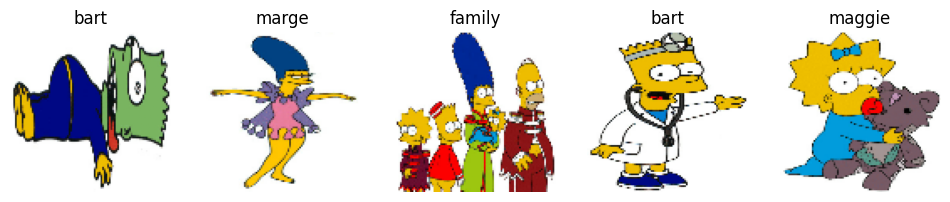

tf.Tensor([0 4 4 5 0 3 2 1 1 2 0 3 2 4 0 3 5 0 0 2 5 0 2 2 2 5 0 1 3 0 1 1], shape=(32,), dtype=int32)


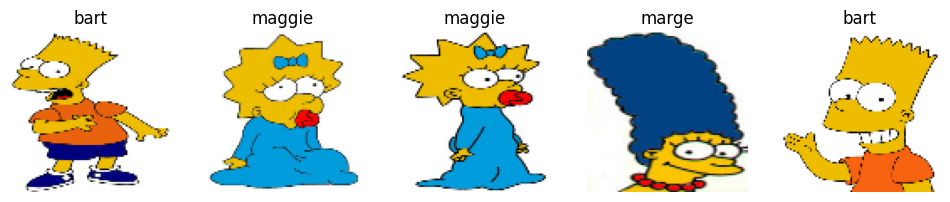

tf.Tensor([2 0 3 0 0 0 4 0 2 5 0 1 0 2 3 2 0 0 4 5 5 4 4 0 1 2 3 0 4 0 5 4], shape=(32,), dtype=int32)


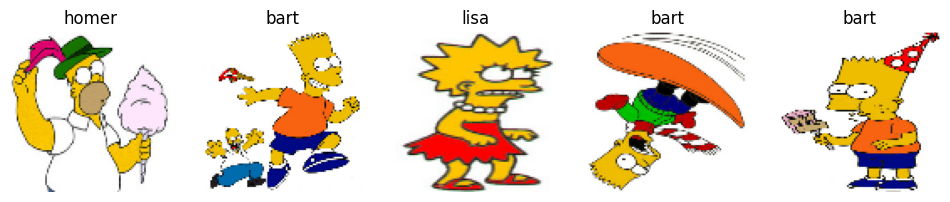

tf.Tensor([2 4 0 1 0 3 3 2 2 5 0 2 2 2 0 0 0 3 5 1 0 3 1 4 2 1 3 3 4 4 2 1], shape=(32,), dtype=int32)


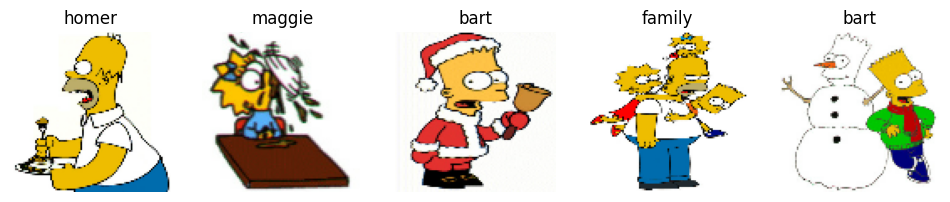

tf.Tensor([0 4 4 4 0 2 5 4 4 2 3 5 1 4 2 3 3 0 0 0 2 1 2 0 0 2 0 2 0 5 0 3], shape=(32,), dtype=int32)


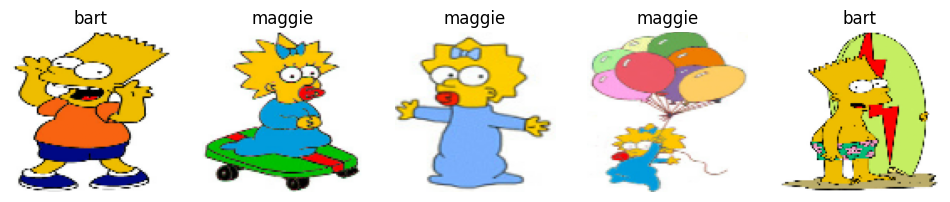

In [6]:
class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)
class_names = np.array(class_names)
for img,lbl in train_ds.take(5):

  titles = []
  print(lbl)
  for i in lbl:
    titles.append(class_names[i])

  plot_sidebyside(img[:5]/255.,titles[:5])

In [7]:
y_train = []
x_train = []
#test_ds = test_ds.map(lambda x, y: (layers.Rescaling(1./255)(x), y))

for img, labels in train_ds:
    y_train.extend(labels.numpy())
    x_train.extend(img)

y_train = np.array(y_train)
x_train = np.array(x_train)

In [8]:
ret = np.unique(y_train,return_counts=True)
print(class_names)
print(ret)

['bart' 'family' 'homer' 'lisa' 'maggie' 'marge']
(array([0, 1, 2, 3, 4, 5], dtype=int32), array([61, 22, 46, 30, 25, 19]))


In [9]:
model = models.Sequential()

#Feature Learning (Convolutions)
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(128, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))
######################################

# Fully-Connect (Classifcation)
model.add(layers.Dropout(0.25))
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dense(num_classes,activation='softmax'))



model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 2, 2, 32)       │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,838 (1.03 MB)

 Trainable params: 268,838 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
epochs_ = 10
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 374ms/step - acc: 0.1773 - loss: 3.6294 - val_acc: 0.3200 - val_loss: 1.7968
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 336ms/step - acc: 0.2709 - loss: 1.7755 - val_acc: 0.3600 - val_loss: 1.6362
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 390ms/step - acc: 0.3054 - loss: 1.7341 - val_acc: 0.3400 - val_loss: 1.6017
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 353ms/step - acc: 0.3054 - loss: 1.7191 - val_acc: 0.3400 - val_loss: 1.7527
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 331ms/step - acc: 0.3005 - loss: 1.6889 - val_acc: 0.3400 - val_loss: 1.5081
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 356ms/step - acc: 0.3153 - loss: 1.6645 - val_acc: 0.4600 - val_loss: 1.5300
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step - acc: 0.3350 - loss: 1.6327 - val_acc: 0.3400 - val_loss: 1.7445
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 393ms/step - acc: 0.3005 - loss: 1.7393 - val_acc: 0.3400 - val_loss: 1.7346
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 317ms/step - acc: 0.3005 - loss: 

dict_keys(['acc', 'loss', 'val_acc', 'val_loss'])


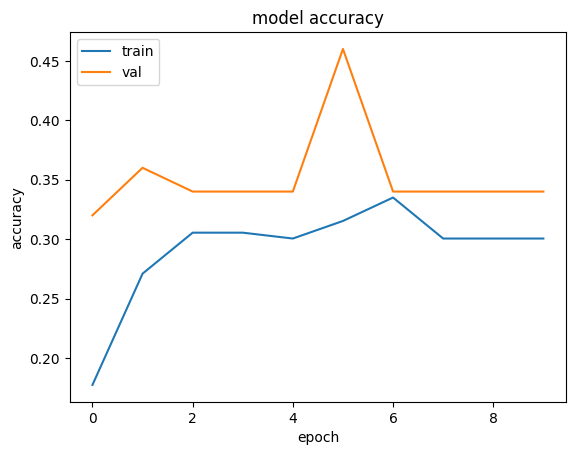

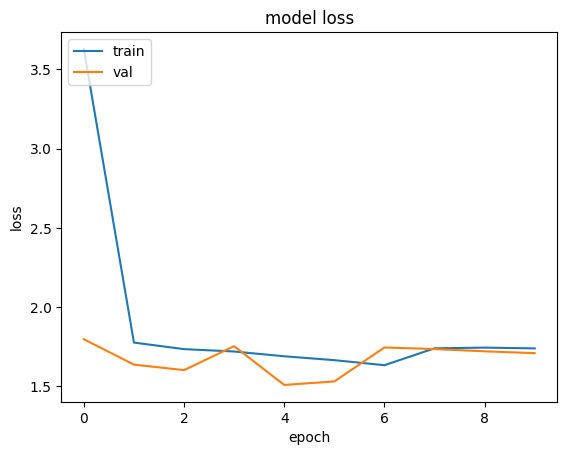

In [11]:
plot_history(history)

In [12]:
model = models.Sequential()

#Feature Learning (Convolutions)
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.Conv2D(128, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=input_shape_))
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape_))

######################################

# Fully-Connect (Classifcation)
model.add(layers.Dropout(0.10))
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dense(num_classes,activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 43, 43, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 39, 39, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 39, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 48672)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │    24,920,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,172,518 (96.03 MB)

 Trainable params: 25,172,518 (96.03 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
epochs_ = 10
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.1724 - loss: 142.9572 - val_acc: 0.1000 - val_loss: 1.8231
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.1034 - loss: 1.7916 - val_acc: 0.3000 - val_loss: 1.8973
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2217 - loss: 1.7929 - val_acc: 0.3000 - val_loss: 1.9546
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2266 - loss: 1.7843 - val_acc: 0.3000 - val_loss: 1.8608
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2266 - loss: 1.7794 - val_acc: 0.3000 - val_loss: 1.8333
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.2266 - loss: 1.7749 - val_acc: 0.3000 - val_loss: 1.8168
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2266 - loss: 1.7682 - val_acc: 0.3000 - val_loss: 1.8018
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.2266 - loss: 1.7622 - val_acc: 0.3000 - val_loss: 1.7847
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2266 - loss: 1.7543 - val_acc

#Data Augmentation

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


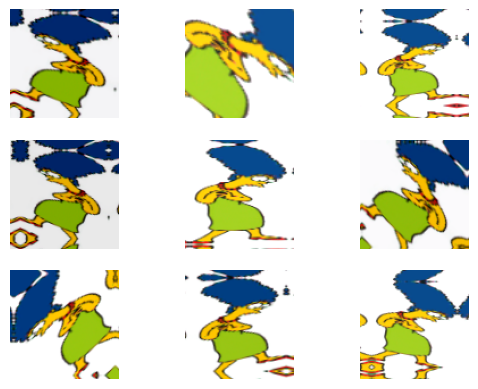

In [14]:
data_augmentation = tf.keras.Sequential(
  [
    layers.RandomFlip("horizontal",
                      input_shape=(input_shape_[0],
                                  input_shape_[1],
                                  3)),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.3),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomContrast(0.1)
  ]
)

for images, _ in train_ds.take(2):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

In [15]:
model = tf.keras.Sequential([
  data_augmentation, #Data Augmentation
  layers.Rescaling(1./255, input_shape=(96, 96, 3)),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.Conv2D(128, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.Conv2D(32, 3, padding='same', activation='relu'),

  layers.Dropout(0.1), #Regularization
  layers.Flatten(),
  layers.Dense(512, activation='relu'),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])


model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     9,437,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,689,638 (36.96 MB)

 Trainable params: 9,689,638 (36.96 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
epochs_ = 10
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.2217 - loss: 2.0693 - val_acc: 0.3400 - val_loss: 1.7336
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - acc: 0.2611 - loss: 1.7774 - val_acc: 0.3400 - val_loss: 1.6892
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 991ms/step - acc: 0.3005 - loss: 1.6965 - val_acc: 0.3400 - val_loss: 1.6471
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 971ms/step - acc: 0.3005 - loss: 1.7032 - val_acc: 0.3400 - val_loss: 1.6595
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - acc: 0.3005 - loss: 1.6993 - val_acc: 0.3400 - val_loss: 1.6246
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.3005 - loss: 1.6735 - val_acc: 0.3400 - val_loss: 1.5553
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - acc: 0.3153 - loss: 1.5753 - val_acc: 0.3600 - val_loss: 1.4603
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - acc: 0.4729 - loss: 1.3642 - val_acc: 0.5200 - val_loss: 1.2113
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.4483 - loss: 1.2952 - val_acc

dict_keys(['acc', 'loss', 'val_acc', 'val_loss'])


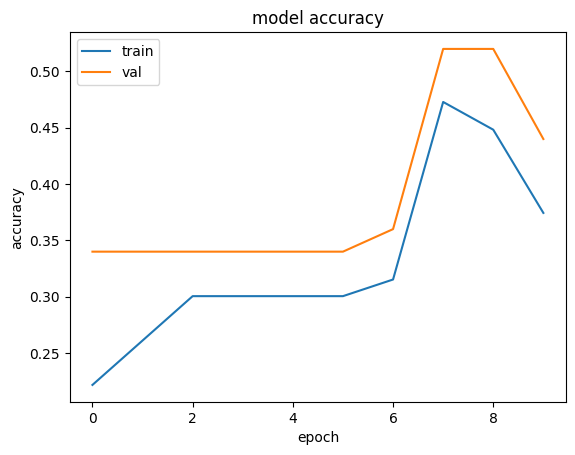

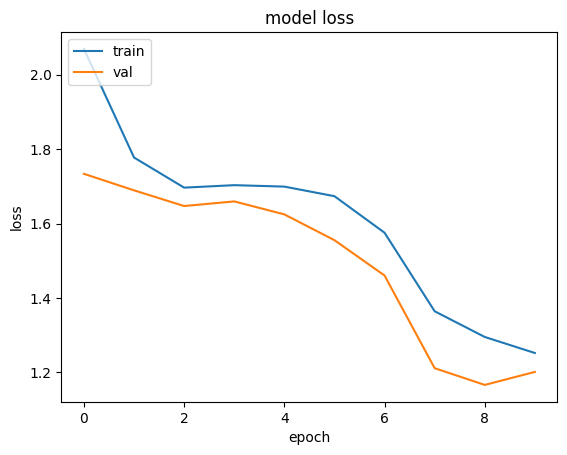

In [17]:
plot_history(history)

#Transfer Learning

In [18]:
conv_layers =  tf.keras.applications.resnet50.ResNet50(weights='imagenet', include_top=False,
                                                        input_tensor=tf.keras.layers.Input(input_shape_),
                                                      classes=num_classes)
conv_layers.trainable = False


conv_layers.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 102, 102,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 48, 48,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 48, 48,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 48, 48,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 50, 50,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 24, 24,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 24, 24,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 24, 24,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 24, 24,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 24, 24,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 24, 24,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 24, 24,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 24, 24,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 24, 24,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [19]:
model = tf.keras.Sequential([
  layers.Input(shape=input_shape_),
  conv_layers,
  layers.GlobalAveragePooling2D(),
  layers.Dropout(0.2),

  layers.Flatten(),

  layers.Dense(256, activation='relu'),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model.summary()

epochs_ = 20
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,145,926 (92.11 MB)

 Trainable params: 558,214 (2.13 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - acc: 0.3202 - loss: 2.3392 - val_acc: 0.4000 - val_loss: 1.4776
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 888ms/step - acc: 0.5862 - loss: 1.0693 - val_acc: 0.4800 - val_loss: 1.5720
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 749ms/step - acc: 0.7291 - loss: 0.7275 - val_acc: 0.5200 - val_loss: 1.3086
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 777ms/step - acc: 0.8768 - loss: 0.4045 - val_acc: 0.6400 - val_loss: 1.1867
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 717ms/step - acc: 0.8916 - loss: 0.3466 - val_acc: 0.6600 - val_loss: 1.0553
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 860ms/step - acc: 0.9163 - loss: 0.2647 - val_acc: 0.6200 - val_loss: 1.1286
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - acc: 0.9458 - loss: 0.1941 - val_acc: 0.6200 - val_loss: 1.1406
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 754ms/step - acc: 0.9704 - loss: 0.1238 - val_acc: 0.6400 - val_loss: 1.2526
Epoch 9/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 809ms/step - acc: 0.9704 - loss: 0

In [20]:
model = tf.keras.Sequential([
  layers.Input(shape=input_shape_),
  conv_layers,
  layers.GlobalAveragePooling2D(),
  layers.Dropout(0.2),

  layers.Flatten(),

  layers.Dense(256, activation='relu'),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model.summary()

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/my_model/model_checkpoint.weights.h5',  # Specify the file to save the weights
    save_best_only=True,             # Save only the best model
    save_weights_only=True,
    monitor='val_acc' ,              # Monitoring validation loss
    mode='max',
    verbose=1
)

epochs_ = 20
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds, callbacks=[checkpoint_callback])


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,145,926 (92.11 MB)

 Trainable params: 558,214 (2.13 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - acc: 0.2286 - loss: 2.8794
Epoch 1: val_acc improved from None to 0.34000, saving model to /content/my_model/model_checkpoint.weights.h5

Epoch 1: finished saving model to /content/my_model/model_checkpoint.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - acc: 0.2956 - loss: 2.5187 - val_acc: 0.3400 - val_loss: 1.8341
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - acc: 0.6157 - loss: 1.1029
Epoch 2: val_acc improved from 0.34000 to 0.52000, saving model to /content/my_model/model_checkpoint.weights.h5

Epoch 2: finished saving model to /content/my_model/model_checkpoint.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 841ms/step - acc: 0.6453 - loss: 1.0011 - val_acc: 0.5200 - val_loss: 1.2862
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 581ms/step - acc: 0.7134 - loss: 0.7455
Epoch 3: val_acc improved from 0.52000 to 0.54000, saving model to /content/my_model/model_checkpoint.weights.h5

Epoch 3: finished saving model to /content/my_model/mode

In [21]:
!ls -lah /content/my_model/model_checkpoint.weights.h5

-rw-r--r-- 1 root root 97M Oct 16 20:12 /content/my_model/model_checkpoint.weights.h5


In [22]:
test_ds = tf.keras.utils.image_dataset_from_directory(
  f'./Simpsons/Teste/',
  seed=seed_number,
  image_size=(input_shape_[0], input_shape_[1]),
  batch_size=batch_size_)

Found 106 files belonging to 6 classes.


In [23]:
model.evaluate(test_ds)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 477ms/step - acc: 0.6887 - loss: 1.9259


[1.925872802734375, 0.6886792182922363]

In [24]:
model.load_weights('/content/my_model/model_checkpoint.weights.h5')
model.evaluate(test_ds)

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 591ms/step - acc: 0.6132 - loss: 1.7899


[1.7898873090744019, 0.6132075190544128]

#Transfer Leaning => Fine Tunning das ultimas 2 camadas de convolução!

In [25]:
conv_layers.trainable=True

n_layers = len(conv_layers.layers)
print(n_layers)
for j in range(0,n_layers-7):
    conv_layers.layers[j].trainable = False



for j in range(n_layers-7,n_layers):
    conv_layers.layers[j].trainable = True

conv_layers.summary()
#base_model.layers[j].trainable = True

175


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 102, 102,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 48, 48,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 48, 48,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 48, 48,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 50, 50,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 24, 24,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 24, 24,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 24, 24,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 24, 24,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 24, 24,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 24, 24,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 24, 24,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 24, 24,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 24, 24,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 3,415,552 (13.03 MB)

 Non-trainable params: 20,172,160 (76.95 MB)

In [26]:
model = tf.keras.Sequential([
  layers.Input(shape=input_shape_),

  conv_layers,
  layers.GlobalAveragePooling2D(),
  layers.Dropout(0.3),

  layers.Flatten(),
  #layers.Dense(512, activation='relu'),
  layers.Dense(256, activation='relu'),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model.summary()

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/my_model/model_checkpoint.weights.h5',  # Specify the file to save the weights
    save_best_only=True,             # Save only the best model
    save_weights_only=True,
    monitor='val_acc' ,              # Monitoring validation loss
    mode='max',
    verbose=1
)

epochs_ = 20
model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["acc"])
history = model.fit(train_ds, batch_size=batch_size_, epochs=epochs_, validation_data=val_ds, callbacks=[checkpoint_callback])


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,145,926 (92.11 MB)

 Trainable params: 3,973,766 (15.16 MB)

 Non-trainable params: 20,172,160 (76.95 MB)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 902ms/step - acc: 0.3321 - loss: 2.1258
Epoch 1: val_acc improved from None to 0.56000, saving model to /content/my_model/model_checkpoint.weights.h5

Epoch 1: finished saving model to /content/my_model/model_checkpoint.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - acc: 0.3941 - loss: 1.8476 - val_acc: 0.5600 - val_loss: 1.3636
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 882ms/step - acc: 0.8266 - loss: 0.5468
Epoch 2: val_acc did not improve from 0.56000
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - acc: 0.8227 - loss: 0.5426 - val_acc: 0.5400 - val_loss: 1.6785
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 913ms/step - acc: 0.9079 - loss: 0.2754
Epoch 3: val_acc did not improve from 0.56000
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.9113 - loss: 0.2579 - val_acc: 0.5400 - val_loss: 1.6921
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 809ms/step - acc: 0.9706 - loss: 0.1354
Epoch 4: val_acc did not improve from 0.56000
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - acc: 0.9

tf.Tensor([1 3 0 3 5 0 3 1 0 2 4 3 0 1 1 1 2 2 2 4 2 0 1 5 2 4 3 0 4 3 0 0], shape=(32,), dtype=int32)
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


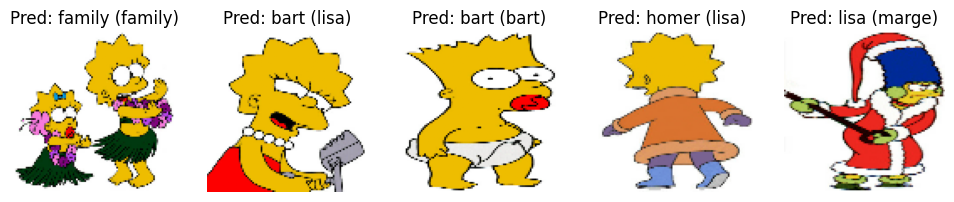

In [27]:
import numpy as np
for img, lbl in test_ds.take(1):
  print(lbl)
  prediction = model.predict(img)
  predicted_labels = np.argmax(prediction, axis=1)
  titles = []
  for t,p in zip(lbl,predicted_labels):
    titles.append(f'Pred: {class_names[p]} ({class_names[t]})')

  plot_sidebyside(img[:5] / 255., titles[:5])



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 730ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 668ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 724ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


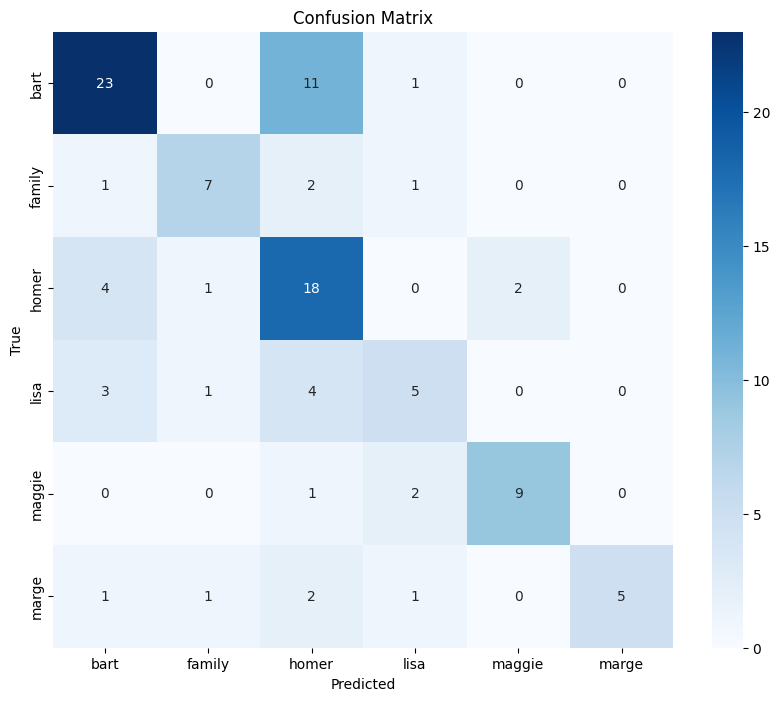

              precision    recall  f1-score   support

        bart       0.72      0.66      0.69        35
      family       0.70      0.64      0.67        11
       homer       0.47      0.72      0.57        25
        lisa       0.50      0.38      0.43        13
      maggie       0.82      0.75      0.78        12
       marge       1.00      0.50      0.67        10

    accuracy                           0.63       106
   macro avg       0.70      0.61      0.63       106
weighted avg       0.67      0.63      0.64       106



In [28]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:
  predictions = model.predict(images)
  predicted_labels = np.argmax(predictions, axis=1)
  y_true.extend(labels.numpy())
  y_pred.extend(predicted_labels)

cm = confusion_matrix(y_true, y_pred)
# Plot the confusion matrix using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Generate and print the classification report
report = classification_report(y_true, y_pred, target_names=class_names)
print(report)
